# Example of the AiTLAS toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import DFC2022Dataset
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
import matplotlib.pyplot as plt

## Show images and masks

Total number of patches: 766


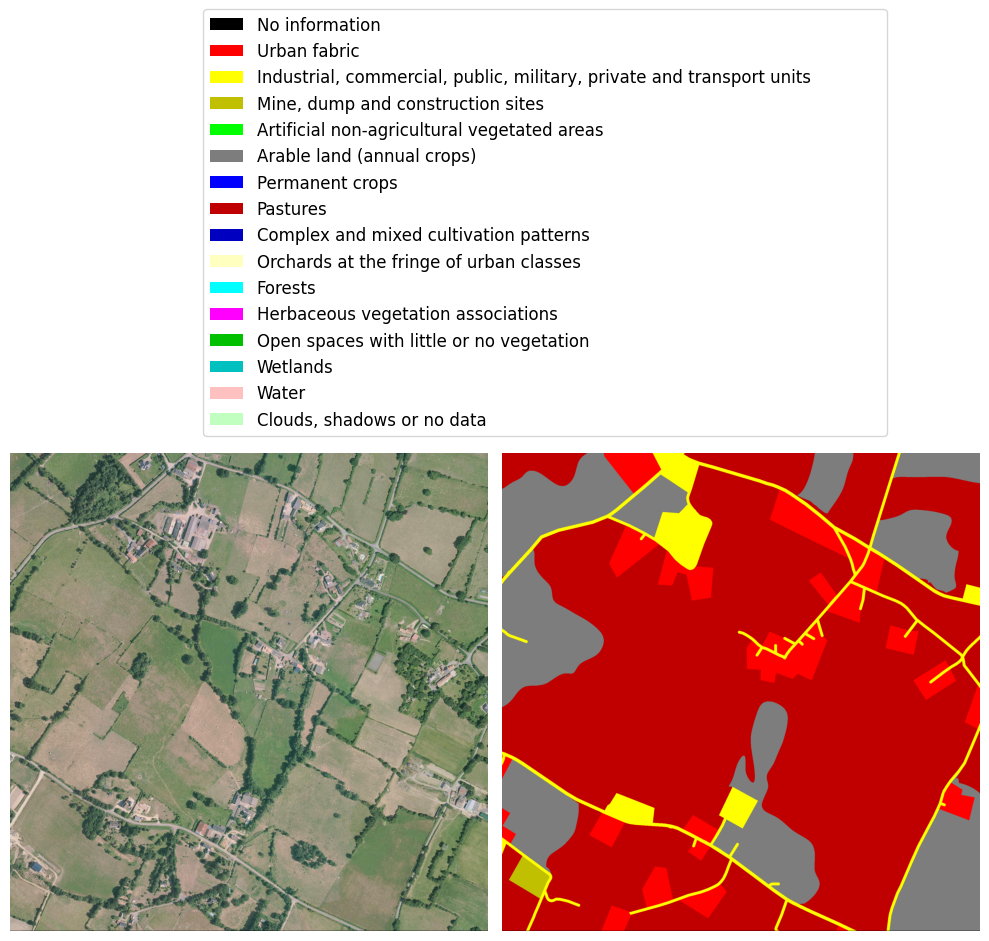

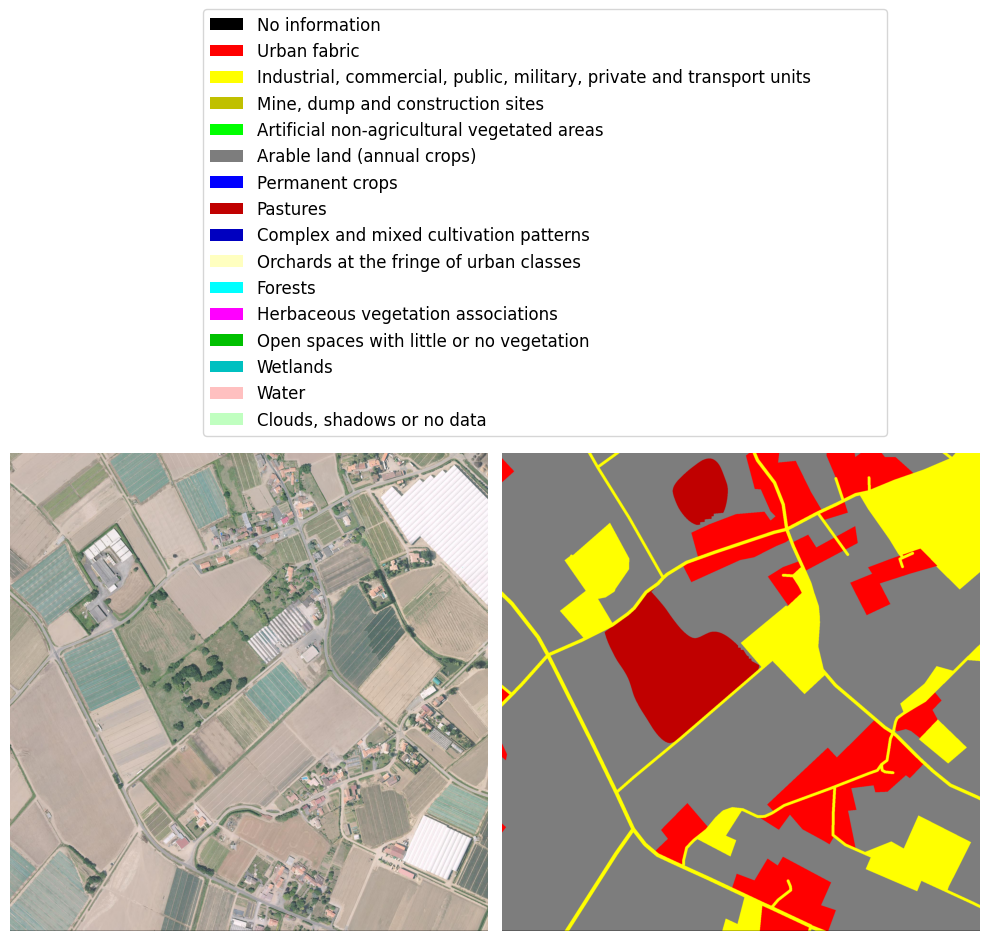

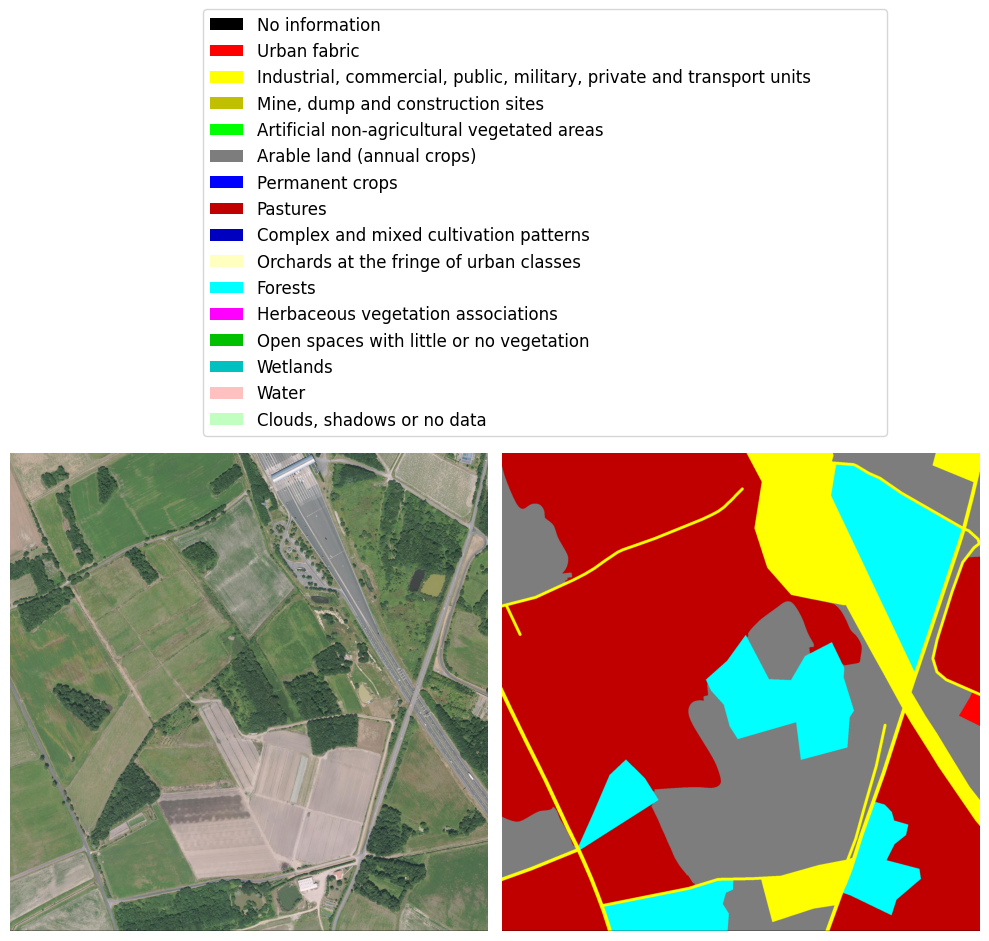

In [ ]:
dataset_config = {
    "data_dir": "./data/grss_dfc_2022/labeled_train"
}
dataset = DFC2022Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(20);
dataset.show_image(50);
dataset.show_image(65);

In [43]:
dataset.data_distribution_table()

,Number of pixels
No information,699637773.0
Urban fabric,211881845.0
"Industrial, commercial, public, military, private and transport units",132005774.0
"Mine, dump and construction sites",10328515.0
Artificial non-agricultural vegetated areas,26641490.0
Arable land (annual crops),246639465.0
Permanent crops,40317005.0
Pastures,722093793.0
Complex and mixed cultivation patterns,0.0
Orchards at the fringe of urban classes,0.0


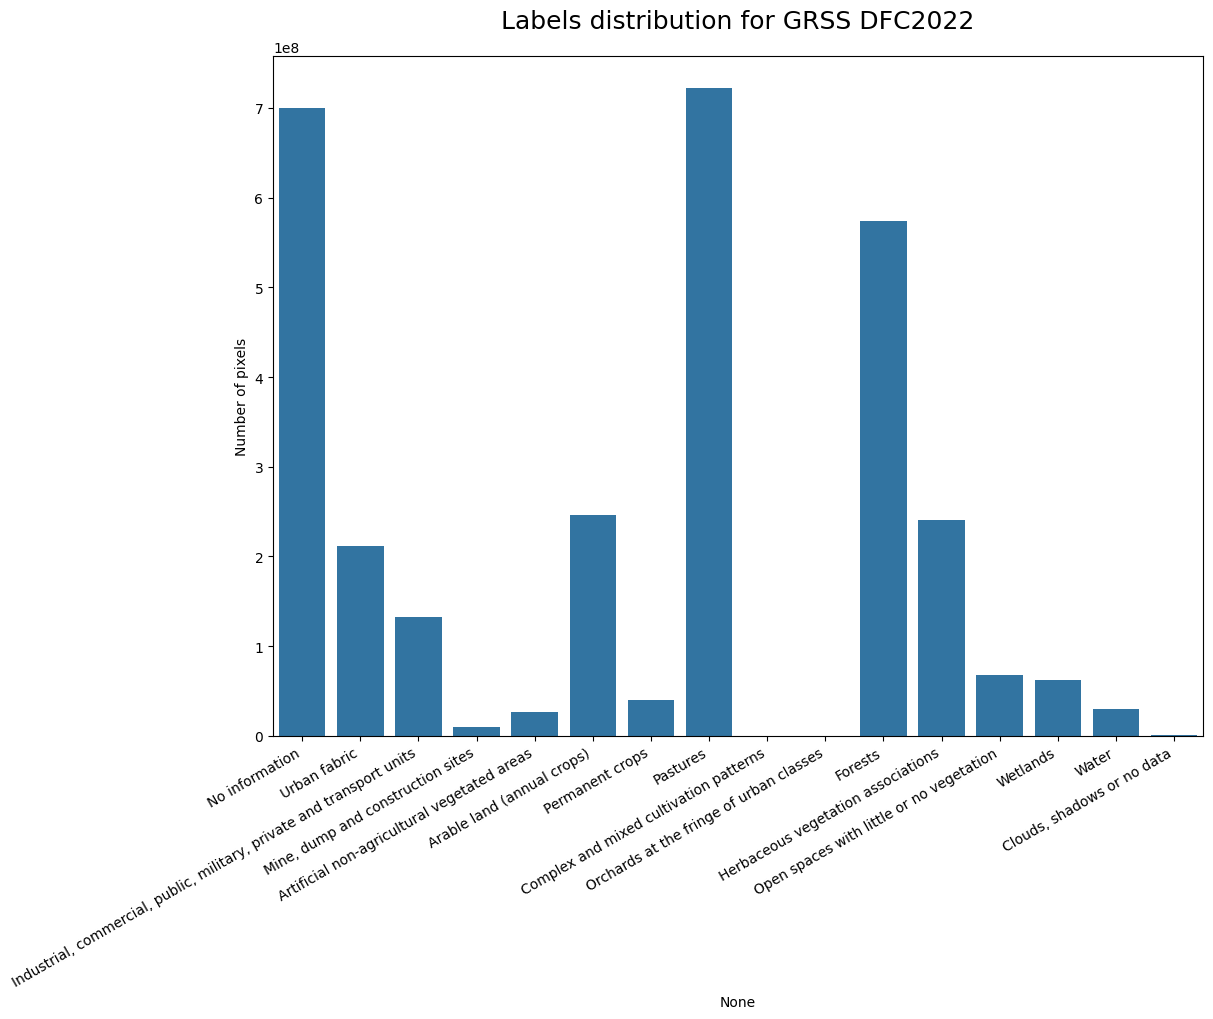

In [44]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/grss_dfc_2022/labeled_train/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = DFC2022Dataset(train_dataset_config)
len(train_dataset)

766

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/experiments/grss_dfc_2022"
model_config = {
    "num_classes": 16, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-12-29 13:26:06,501 INFO Starting training.
training: 100%|██████████| 96/96 [02:17<00:00,  1.43s/it]
2025-12-29 13:28:23,605 INFO epoch: 1, time: 137, loss:  0.84544
testing on train set: 100%|██████████| 96/96 [02:13<00:00,  1.39s/it]
2025-12-29 13:30:39,097 INFO IOU:0.24609854563847747, IOU mean:0.14317299212443146, IOU per Class:[0.24127743 0.24552098 0.13896649 0.         0.         0.142465
 0.2761078  0.42960514 0.         0.         0.32265422 0.18977461
 0.11022864 0.18502688 0.00914069 0.        ]
training: 100%|██████████| 96/96 [02:19<00:00,  1.45s/it]
2025-12-29 13:32:58,783 INFO epoch: 2, time: 139, loss:  0.78522
testing on train set: 100%|██████████| 96/96 [02:17<00:00,  1.44s/it]
2025-12-29 13:35:16,597 INFO IOU:0.2777196637573648, IOU mean:0.181333728147554, IOU per Class:[0.23034355 0.31092698 0.16222778 0.         0.         0.14710908
 0.42237442 0.42483412 0.         0.         0.37283837 0.27777451
 0.11857781 0.43433302 0.         0.        ]
training: 100%|

## Predictions

2025-12-30 10:42:52,705 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/grss_dfc_2022/checkpoint.pth.tar
2025-12-30 10:42:53,065 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/grss_dfc_2022/checkpoint.pth.tar at epoch 11


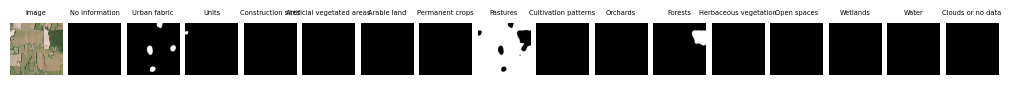

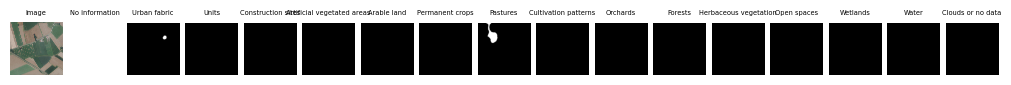

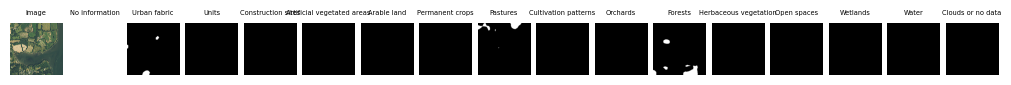

In [ ]:
model_path = "./data/experiments/grss_dfc_2022/checkpoint.pth.tar"
labels = ["No information","Urban fabric","Units","Construction sites","Artificial vegetated areas","Arable land","Permanent crops","Pastures",
          "Cultivation patterns","Orchards","Forests","Herbaceous vegetation","Open spaces","Wetlands","Water","Clouds or no data"]
transform = ResizeToTensor()
model.load_model(model_path)
plt.rcParams.update({'font.size': 4})

image = image_loader('./data/grss_dfc_2022/val/Angers/BDORTHO/49-2013-0396-6721-LA93-0M50-E080.tif')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/grss_dfc_2022/val/Lille_Arras_Lens_Douai_Henin/BDORTHO/59-2012-0685-7069-LA93-0M50-E080.tif')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/grss_dfc_2022/val/Quimper/BDORTHO/29-2012-0169-6786-LA93-0M50-E080.tif')
fig = model.predict_masks(image, labels, transform)